# Assignment 5

Smoothing with an averaging filter, the weighted filter h(x, y) = max(|x|, |y|), and a Gaussian filter.

Sample: `sample_portrait.jpg`. Filter size 5, sigma 1.2, replication padding. The second figure zooms in on the eyes and the hair.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt


# smoothing
# 1. plain average (box) filter
# 2. weighted filter h(x, y) = max(|x|, |y|), x and y measured from the centre
# 3. gaussian
# size, sigma and padding come from the user

def average_kernel(size):
    return np.ones((size, size), dtype=np.float64) / float(size * size)


def weighted_kernel(size):
    # centre of the window is (0, 0), so the middle weight is 0
    half = size // 2
    ax = np.arange(-half, half + 1)
    xx, yy = np.meshgrid(ax, ax)
    h = np.maximum(np.abs(xx), np.abs(yy)).astype(np.float64)
    total = h.sum()
    if total == 0:
        h[half, half] = 1.0
        total = 1.0
    # divide by the sum so this stays an averaging filter
    return h / total


def gaussian_kernel(size, sigma):
    half = size // 2
    ax = np.arange(-half, half + 1)
    xx, yy = np.meshgrid(ax, ax)
    h = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma * sigma))
    return h / h.sum()


def apply_filter(img, kernel, border):
    acc = cv2.filter2D(img.astype(np.float64), cv2.CV_64F, kernel, borderType=border)
    return np.clip(np.round(acc), 0, 255).astype(np.uint8)


sample image: sample_portrait.jpg (256, 256)
padding: replication
average kernel sums to 1.0
weighted kernel h = max(|x|, |y|), sums to 1.0
weighted kernel:
[[0.05  0.05  0.05  0.05  0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.025 0.    0.025 0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.05  0.05  0.05  0.05 ]]
gaussian kernel sums to 1.0


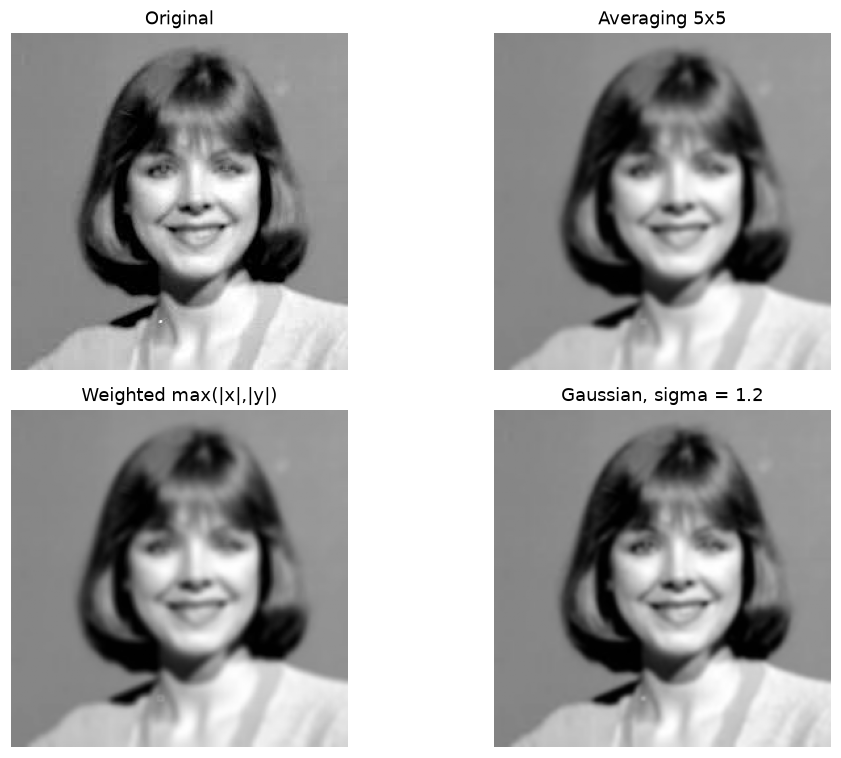

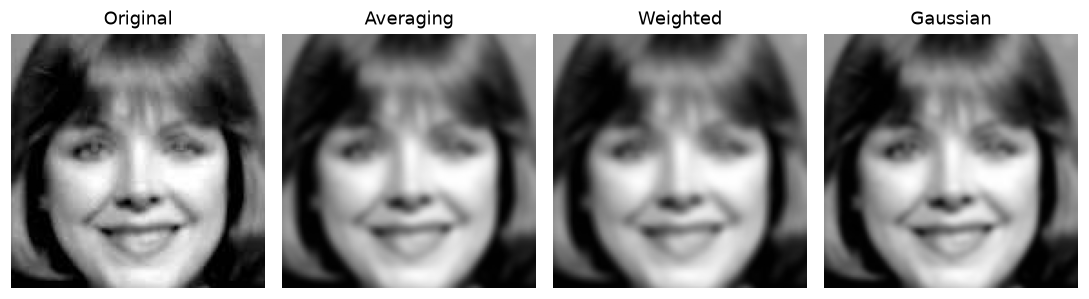

In [2]:
image_path = "sample_portrait.jpg"
size = 5
sigma = 1.2
border = cv2.BORDER_REPLICATE
pad_name = "replication"

img = cv2.imread(image_path, 0)
print("sample image:", image_path, img.shape)

k_avg = average_kernel(size)
k_w = weighted_kernel(size)
k_g = gaussian_kernel(size, sigma)

print("padding:", pad_name)
print("average kernel sums to", round(k_avg.sum(), 4))
print("weighted kernel h = max(|x|, |y|), sums to", round(k_w.sum(), 4))
print("weighted kernel:")
print(np.round(k_w, 4))
print("gaussian kernel sums to", round(k_g.sum(), 4))

out_avg = apply_filter(img, k_avg, border)
out_w = apply_filter(img, k_w, border)
out_g = apply_filter(img, k_g, border)

plt.figure(figsize=(10, 7))
plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(out_avg, cmap="gray", vmin=0, vmax=255)
plt.title("Averaging " + str(size) + "x" + str(size))
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(out_w, cmap="gray", vmin=0, vmax=255)
plt.title("Weighted max(|x|,|y|)")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(out_g, cmap="gray", vmin=0, vmax=255)
plt.title("Gaussian, sigma = " + str(sigma))
plt.axis("off")
plt.tight_layout()

# eyes and hair, so the blur is easy to see
y0, x0, side = 40, 70, 140
zoom = [
    (img, "Original"),
    (out_avg, "Averaging"),
    (out_w, "Weighted"),
    (out_g, "Gaussian"),
]
plt.figure(figsize=(10, 3.2))
for i, (pic, title) in enumerate(zoom):
    plt.subplot(1, 4, i + 1)
    plt.imshow(pic[y0:y0 + side, x0:x0 + side], cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()
